# 🌲 지도학습 모델 비교 — RandomForest vs XGBoost (+ 반복 교차검증)

- **목적**: 클래스 불균형을 반영한 두 트리 모델을 학습하고, Validation에서 임계값별 탐지율·검토 건수를 비교해 운영 임계값 후보를 정합니다.
- **선택 기준**: Recall ≥ 0.80인 임계값 후보 중 총 검토 건수(TP+FP)가 가장 적은 것
- **선행**: `eda_and_split.ipynb`
- **산출물**: `reports/tables/supervised_val_metrics.csv`, `supervised_val_thresholds.csv`, `supervised_val_candidates.csv`, `reports/figures/rf_validation_simulation.png`, `xgb_validation_simulation.png`
- **추가 실험 (6장)**: 반복 교차검증으로 LogReg / RF / XGBoost / LightGBM, class_weight vs SMOTE 비교 → `supervised_cv_folds.csv`, `supervised_cv_summary.csv`
- **원칙**: Test 데이터는 사용하지 않습니다. (최종 평가는 `final_report.ipynb`)

## 1. 환경 설정 및 데이터 로드

In [1]:
import sys
from pathlib import Path

print("사용 중인 파이썬:", sys.executable)
print("현재 작업 폴더:", Path.cwd())

사용 중인 파이썬: /home/user1/anaconda3/envs/dkenv/bin/python3.10
현재 작업 폴더: /home/user1/study/credit-card-fds/experiments


In [2]:
# 프로젝트 최상위 폴더
PROJECT_ROOT = Path.cwd().parent

# 공통 함수가 있는 src 폴더를 파이썬 검색 경로에 추가
sys.path.insert(0, str(PROJECT_ROOT / "src"))

from utils import (
    load_and_preprocess_data,
    evaluate_fds_model,
    evaluate_thresholds,
    plot_and_save_simulation,
)

# 데이터를 불러올 위치와 결과 CSV를 저장할 위치
DATA_DIR = PROJECT_ROOT / "data" / "processed"
TABLE_DIR = PROJECT_ROOT / "reports" / "tables"          # 결과표(CSV) 저장 위치
TABLE_DIR.mkdir(parents=True, exist_ok=True)

X_train, y_train, X_val, y_val = load_and_preprocess_data(DATA_DIR)

print("학습 데이터:", X_train.shape)
print("검증 데이터:", X_val.shape)

[Data Loaded] Train: (198624, 30), Validation: (42561, 30)
학습 데이터: (198624, 30)
검증 데이터: (42561, 30)


## 2. 랜덤포레스트 (class_weight='balanced')

In [3]:
#랜덤 포레스트 학습시켜주기
from sklearn.ensemble import RandomForestClassifier

# n_estimators = 200: 나무(Decision Tree)를 총 200개 만들어 숲을 구성했습니다. 기본값(100개)보다 넉넉하게 주어 모델의 안정성과 정확도를 높였습니다.
# n_jobs = -1: 컴퓨터의 모든 CPU 코어를 동원해서 병렬로 학습을 빠르게 돌리겠다는 뜻입니다. (속도 향상에 필수적인 좋은 설정입니다.)
# class_weight = 'balanced': 사기 데이터가 전체의 0.17%로 극도로 적을 때, 모델이 정상 거래만 맞히는 걸 방지하기 위해 사기 데이터 쪽에 가중치를 자동으로 훅 실어주는 옵션입니다. FDS에서 필수적인 설정입니다.
# max_depth = None: 트리가 뻗어 나갈 수 있는 최대 깊이에 제한을 두지 않고 완벽하게 학습하게 뒀습니다.
# min_samples_split = 2 / min_samples_leaf = 1: 노드를 쪼개거나 잎사귀 노드가 되기 위한 최소 샘플 수의 기본값입니다.
# max_features = 'sqrt': 각 트리가 분기할 때 전체 피처(30개) 중 무작위로 $\sqrt{30} \approx 5.47$, 즉 약 5~6개의 피처만 골라서 다양성을 높입니다. 랜덤 포레스트의 핵심 장점인 '무작위성'을 잘 살린 설정입니다.
rf_model = RandomForestClassifier(
    n_estimators=200,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1,
)

print("랜덤포레스트 학습 시작")

rf_model.fit(X_train, y_train)

print("랜덤포레스트 학습 완료!")

랜덤포레스트 학습 시작


랜덤포레스트 학습 완료!


In [4]:
# ============================================================
# 랜덤포레스트 검증 성능 평가
# ============================================================
# 목적: 학습한 모델을 검증 데이터에 적용하여 사기 탐지 성능 확인
# 예측: 사기 클래스(1)의 예측 확률이 0.5 이상이면 사기로 판단
# 평가: 공통 함수 evaluate_fds_model로 AP(PR_AUC), Recall,
#       Precision, F1, Accuracy 및 혼동행렬 건수 산출
# 저장: 4장에서 XGBoost 결과와 통합하여 저장
# 참고: 임계값 0.5에서의 초기 평가이며, 최적 임계값은 아직 선택하지 않음
#       테스트 데이터는 사용하지 않음
# ============================================================
import pandas as pd

# 검증 거래마다 사기일 확률 계산
rf_prob = rf_model.predict_proba(X_val)[:, 1]

# 사기 확률 0.5 이상이면 사기(1), 미만이면 정상(0)
rf_pred = (rf_prob >= 0.5).astype(int)

# 공통 함수로 성능 평가
rf_metrics = evaluate_fds_model(
    "RandomForest", y_val, rf_pred, rf_prob
)

# 평가 결과를 표로 변환
rf_metrics_df = pd.DataFrame([rf_metrics])
rf_metrics_df["Split"] = "validation"
rf_metrics_df["Threshold"] = 0.5



================ [RandomForest] 평가 결과 ================
1. Accuracy  (정확도) : 0.99951
2. PR-AUC    (평균정밀도): 0.85720 ★
3. Recall    (재현율)  : 0.71233
4. Precision (정밀도)  : 1.00000
5. F1-Score  (조화평균): 0.83200
----------------------------------------------------------
Confusion Matrix (혼동행렬):
[[42488     0]
 [   21    52]]
 - TN(정상 예측 성공): 42,488건 | FP(오탐 / 오인 신고): 0건 | FN(미탐 / 놓친 사기): 21건 | TP(사기 탐지 성공): 52건



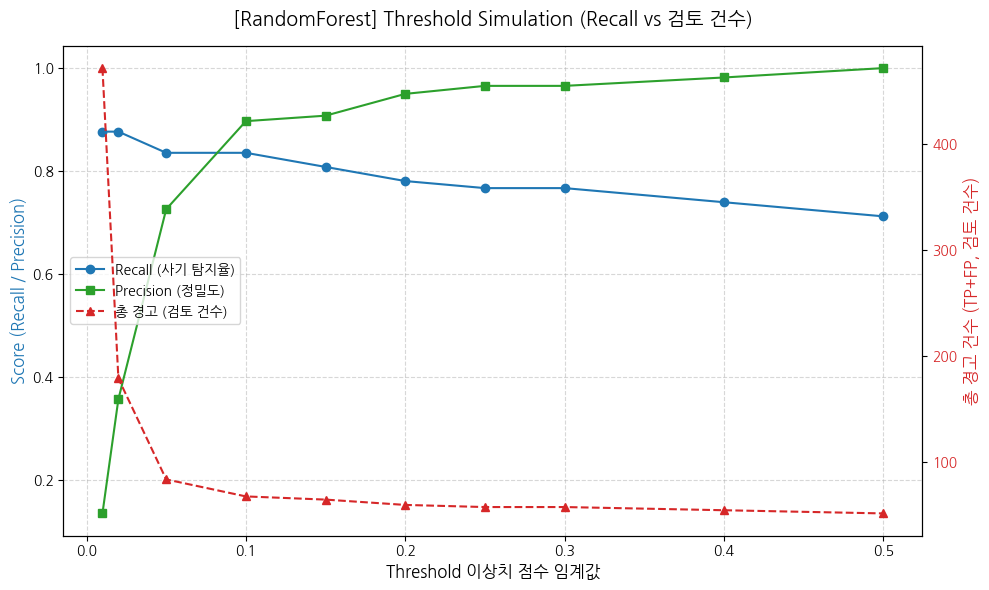

[저장 완료] 그래프 파일: /home/user1/study/credit-card-fds/reports/figures/rf_validation_simulation.png


,Threshold,Recall,Precision,F1-Score,TP (사기 탐지),FP (오탐/검토 대상),FN (놓친 사기),Total Flagged (총 경고),Model,Split
0,0.01,0.876712,0.135881,0.235294,64,407,9,471,RandomForest,validation
1,0.02,0.876712,0.357542,0.507937,64,115,9,179,RandomForest,validation
2,0.05,0.835616,0.726190,0.777070,61,23,12,84,RandomForest,validation
3,0.10,0.835616,0.897059,0.865248,61,7,12,68,RandomForest,validation
4,0.15,0.808219,0.907692,0.855072,59,6,14,65,RandomForest,validation
5,0.20,0.780822,0.950000,0.857143,57,3,16,60,RandomForest,validation
6,0.25,0.767123,0.965517,0.854962,56,2,17,58,RandomForest,validation
7,0.30,0.767123,0.965517,0.854962,56,2,17,58,RandomForest,validation
8,0.40,0.739726,0.981818,0.843750,54,1,19,55,RandomForest,validation
9,0.50,0.712329,1.000000,0.832000,52,0,21,52,RandomForest,validation


In [5]:
# ============================================================
# 랜덤포레스트 임계값별 검토 건수 시뮬레이션
# 목적: 사기 판단 기준을 바꿨을 때 탐지율과 검토 부담 비교
# 주의: 건수는 검증 데이터 전체 기준이며, 하루 기준은 아님
#       총 검토 건수(TP + FP)는 Total Flagged 열에 기록됨
# ============================================================

# 낮은 임계값부터 기존 기준인 0.5까지 비교
rf_thresholds = [
    0.01, 0.02, 0.05, 0.10, 0.15,
    0.20, 0.25, 0.30, 0.40, 0.50,
]

# 공통 함수로 임계값별 성능과 검토 건수 계산
rf_simulation = evaluate_thresholds(
    y_val,
    rf_prob,
    thresholds=rf_thresholds,
)

# 팀원이 모델과 평가 데이터 종류를 구분할 수 있도록 표시
rf_simulation["Model"] = "RandomForest"
rf_simulation["Split"] = "validation"

# 공통 함수로 그래프 출력 및 reports/figures에 저장
# 이 그래프의 오른쪽 축은 총 경고 건수(TP + FP = 상담원 검토 건수)
plot_and_save_simulation(
    rf_simulation,
    model_name="RandomForest",
    filename="rf_validation_simulation.png",
    figures_dir=PROJECT_ROOT / "reports" / "figures",
)

# 임계값별 상세 결과를 표로 표시
display(rf_simulation)

## 3. XGBoost (scale_pos_weight)

In [6]:

# ============================================================
# XGBoost 학습: scale_pos_weight로 클래스 불균형 반영
# 목적: 정상 거래에 비해 매우 적은 사기 거래에 학습 가중치 부여
# 가중치 계산: 학습 데이터의 정상 건수 / 사기 건수
# 주의: 가중치 계산과 학습에는 검증·테스트 데이터를 사용하지 않음
# ============================================================

from xgboost import XGBClassifier

# 학습 데이터에서 정상(0)과 사기(1) 거래 건수 계산
normal_count = int((y_train == 0).sum())
fraud_count = int((y_train == 1).sum())

# 사기 거래가 없으면 가중치를 계산할 수 없으므로 점검
if fraud_count == 0:
    raise ValueError("학습 데이터에 사기 거래가 없습니다.")

pos_weight = normal_count / fraud_count

print("학습 정상 거래:", normal_count)
print("학습 사기 거래:", fraud_count)
print("scale_pos_weight:", pos_weight)

# 초기 비교용 모델 설정이며, 최적화된 설정은 아님
xgb_model = XGBClassifier(
    n_estimators=300,          # 순차적으로 학습할 트리 수
    max_depth=4,               # 트리 깊이를 제한하여 복잡도 조절
    learning_rate=0.05,         # 각 트리가 예측을 수정하는 정도
    subsample=0.8,             # 각 트리 학습에 사용할 행의 비율
    colsample_bytree=0.8,      # 각 트리 학습에 사용할 특성의 비율
    scale_pos_weight=pos_weight,  # 사기 클래스에 적용할 가중치
    objective="binary:logistic",  # 정상·사기 이진 분류
    eval_metric="aucpr",       # XGBoost 내부 평가 지표 설정
    tree_method="hist",        # 히스토그램 기반 트리 학습
    random_state=42,           # 결과 재현을 위한 난수 설정
    n_jobs=-1,                 # 사용 가능한 CPU 코어 활용
)

# 학습 데이터와 정답으로 모델 학습
print("XGBoost 학습 시작")
xgb_model.fit(X_train, y_train)
print("XGBoost 학습 완료!")

학습 정상 거래: 198277
학습 사기 거래: 347
scale_pos_weight: 571.4034582132565
XGBoost 학습 시작


XGBoost 학습 완료!


In [7]:
# ============================================================
# XGBoost 검증 성능 평가
# 목적: 랜덤포레스트와 동일한 검증 데이터·임계값으로 초기 성능 비교
# 평가: 공통 함수 evaluate_fds_model 사용
# 저장: 4장에서 랜덤포레스트 결과와 통합하여 저장
# 주의: 임계값은 0.5이며, 테스트 데이터는 사용하지 않음
# ============================================================

# 검증 거래마다 사기 클래스(1)의 예측 확률 추출
xgb_prob = xgb_model.predict_proba(X_val)[:, 1]

# 사기 예측 확률이 0.5 이상이면 사기(1), 미만이면 정상(0)
xgb_pred = (xgb_prob >= 0.5).astype(int)

# 공통 함수로 AP, Recall, Precision, F1 및 혼동행렬 등 산출
xgb_metrics = evaluate_fds_model(
    "XGBoost", y_val, xgb_pred, xgb_prob
)

# 반환된 딕셔너리를 한 행짜리 표로 변환하고 평가 조건 기록
xgb_metrics_df = pd.DataFrame([xgb_metrics])
xgb_metrics_df["Split"] = "validation"
xgb_metrics_df["Threshold"] = 0.5



================ [XGBoost] 평가 결과 ================
1. Accuracy  (정확도) : 0.99918
2. PR-AUC    (평균정밀도): 0.84182 ★
3. Recall    (재현율)  : 0.82192
4. Precision (정밀도)  : 0.73171
5. F1-Score  (조화평균): 0.77419
----------------------------------------------------------
Confusion Matrix (혼동행렬):
[[42466    22]
 [   13    60]]
 - TN(정상 예측 성공): 42,466건 | FP(오탐 / 오인 신고): 22건 | FN(미탐 / 놓친 사기): 13건 | TP(사기 탐지 성공): 60건



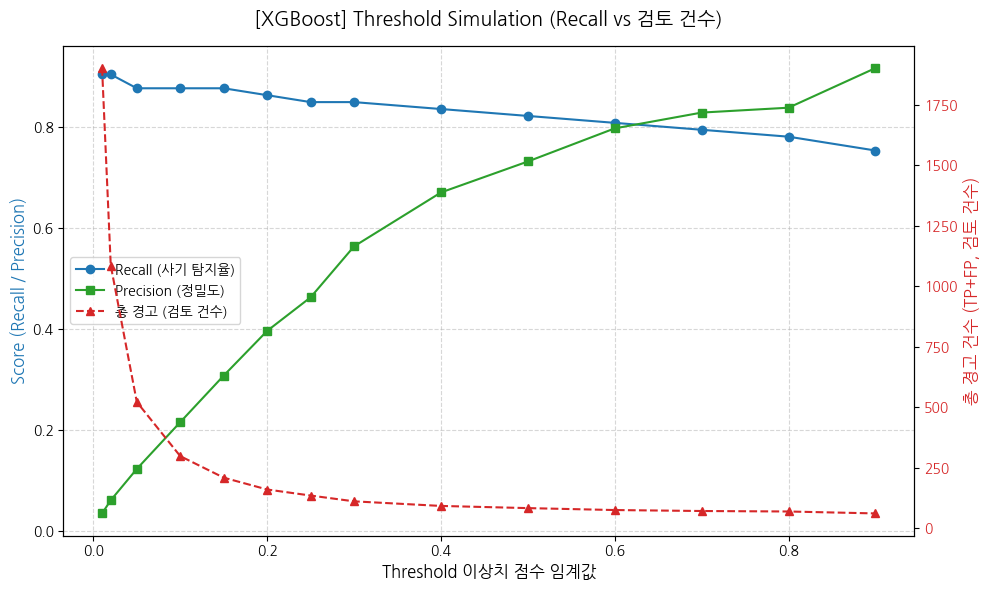

[저장 완료] 그래프 파일: /home/user1/study/credit-card-fds/reports/figures/xgb_validation_simulation.png


,Threshold,Recall,Precision,F1-Score,TP (사기 탐지),FP (오탐/검토 대상),FN (놓친 사기),Total Flagged (총 경고),Model,Split
0,0.01,0.904110,0.034682,0.066802,66,1837,7,1903,XGBoost,validation
1,0.02,0.904110,0.060773,0.113891,66,1020,7,1086,XGBoost,validation
2,0.05,0.876712,0.122841,0.215488,64,457,9,521,XGBoost,validation
3,0.10,0.876712,0.215488,0.345946,64,233,9,297,XGBoost,validation
4,0.15,0.876712,0.307692,0.455516,64,144,9,208,XGBoost,validation
5,0.20,0.863014,0.396226,0.543103,63,96,10,159,XGBoost,validation
6,0.25,0.849315,0.462687,0.599034,62,72,11,134,XGBoost,validation
7,0.30,0.849315,0.563636,0.677596,62,48,11,110,XGBoost,validation
8,0.40,0.835616,0.670330,0.743902,61,30,12,91,XGBoost,validation
9,0.50,0.821918,0.731707,0.774194,60,22,13,82,XGBoost,validation


In [8]:
# ============================================================
# XGBoost 임계값별 검토 건수 시뮬레이션
# 목적: 임계값에 따른 사기 탐지율과 검토 부담 비교
# 범위: 0.01~0.90의 후보를 검증 데이터에서 평가
# 주의: 총 검토 건수는 TP + FP이며, 하루 기준 건수가 아님
# ============================================================

# 0.5보다 낮은 기준과 높은 기준을 함께 검토
xgb_thresholds = [
    0.01, 0.02, 0.05, 0.10, 0.15, 0.20,
    0.25, 0.30, 0.40, 0.50, 0.60, 0.70,
    0.80, 0.90,
]

# 공통 함수로 임계값별 Recall, Precision, 검토 건수 등 산출
xgb_simulation = evaluate_thresholds(
    y_val,
    xgb_prob,
    thresholds=xgb_thresholds,
)

# 결과를 합칠 때 모델과 평가 데이터 종류를 구분하기 위한 열
xgb_simulation["Model"] = "XGBoost"
xgb_simulation["Split"] = "validation"

# 공통 함수로 그래프를 출력하고 reports/figures에 저장
# 오른쪽 축은 총 경고 건수(TP + FP = 상담원 검토 건수)
plot_and_save_simulation(
    xgb_simulation,
    model_name="XGBoost",
    filename="xgb_validation_simulation.png",
    figures_dir=PROJECT_ROOT / "reports" / "figures",
)

# 임계값별 상세 결과 표시
display(xgb_simulation)

## 4. 두 모델 통합 비교 및 운영 임계값 후보 선택

In [9]:
# ============================================================
# 랜덤포레스트·XGBoost 검증 결과 통합 및 운영 후보 비교
# 선택 기준: Recall >= 0.80인 후보 중 총 검토 건수 최소
# 동률 처리: Recall이 높은 순, 그다음 임계값이 높은 순
# 주의: 지금까지 평가한 임계값 후보 안에서만 선택
#       모든 건수는 검증 데이터 전체 기준이며 하루 기준이 아님
#       테스트 데이터는 사용하지 않음
# ============================================================

# 1. 임계값 0.5에서 계산한 두 모델의 핵심 성능지표 통합
comparison_metrics = pd.concat(
    [rf_metrics_df, xgb_metrics_df],
    ignore_index=True,
)

# 통합 성능지표를 reports/tables에 저장 (행 번호 제외, 엑셀 한글 깨짐 방지)
comparison_metrics.to_csv(
    TABLE_DIR / "supervised_val_metrics.csv",
    index=False,
    encoding="utf-8-sig",
)

# 2. 두 모델의 임계값별 시뮬레이션 결과 통합
all_simulations = pd.concat(
    [rf_simulation, xgb_simulation],
    ignore_index=True,
)

# 모든 임계값 후보의 결과를 CSV로 저장
all_simulations.to_csv(
    TABLE_DIR / "supervised_val_thresholds.csv",
    index=False,
    encoding="utf-8-sig",
)

# 3. 목표 Recall 80% 이상을 만족하는 후보만 추출
target_recall = 0.80

eligible = all_simulations[
    all_simulations["Recall"] >= target_recall
].copy()

# 총 검토 건수가 적은 순서로 정렬한 뒤 모델별 첫 행 선택
selected_candidates = (
    eligible.sort_values(
        ["Total Flagged (총 경고)", "Recall", "Threshold"],
        ascending=[True, False, False],
    )
    .drop_duplicates(subset="Model")
    .reset_index(drop=True)
)

# 목표를 만족하는 후보가 없는 모델도 확인
for model_name in ["RandomForest", "XGBoost"]:
    if model_name not in selected_candidates["Model"].values:
        print(f"{model_name}: Recall 80% 이상인 후보가 없습니다.")

# 4. 후보 선택 조건을 기록하고 비교 결과 저장
selected_candidates["Target_Recall"] = target_recall

selected_candidates.to_csv(
    TABLE_DIR / "supervised_val_candidates.csv",
    index=False,
    encoding="utf-8-sig",
)

# 5. 팀원이 비교하기 쉽도록 주요 열만 화면에 표시
print("임계값 후보 중 Recall 80% 이상 · 최소 검토 건수 비교")

display(selected_candidates[[
    "Model",
    "Threshold",
    "Recall",
    "Precision",
    "TP (사기 탐지)",
    "FP (오탐/검토 대상)",
    "FN (놓친 사기)",
    "Total Flagged (총 경고)",
]])

print("통합 CSV 3개 저장 완료!")

임계값 후보 중 Recall 80% 이상 · 최소 검토 건수 비교


,Model,Threshold,Recall,Precision,TP (사기 탐지),FP (오탐/검토 대상),FN (놓친 사기),Total Flagged (총 경고)
0,RandomForest,0.15,0.808219,0.907692,59,6,14,65
1,XGBoost,0.60,0.808219,0.797297,59,15,14,74


통합 CSV 3개 저장 완료!


## 5. 산출물 저장 확인

In [10]:
# ============================================================
# 산출물 저장 확인
# 목적: 팀원에게 전달할 CSV 3개와 그래프 2개의 존재·크기 점검
# CSV는 다시 읽어 행 개수도 확인
# ============================================================

# 두 모델 통합 결과 3개
csv_names = [
    "supervised_val_metrics.csv",
    "supervised_val_thresholds.csv",
    "supervised_val_candidates.csv",
]

# CSV 파일을 다시 읽어 정상적으로 저장됐는지 확인
for name in csv_names:
    path = TABLE_DIR / name
    if path.is_file():
        saved_df = pd.read_csv(path, encoding="utf-8-sig")
        print(f"[확인] {name}: {len(saved_df)}행")
    else:
        print(f"[누락] {name}")

# 모델별 시뮬레이션 그래프 파일 확인
figures_dir = PROJECT_ROOT / "reports" / "figures"

for name in [
    "rf_validation_simulation.png",
    "xgb_validation_simulation.png",
]:
    path = figures_dir / name
    if path.is_file() and path.stat().st_size > 0:
        print(f"[확인] {name}")
    else:
        print(f"[누락 또는 빈 파일] {name}")

[확인] supervised_val_metrics.csv: 2행
[확인] supervised_val_thresholds.csv: 24행
[확인] supervised_val_candidates.csv: 2행
[확인] rf_validation_simulation.png
[확인] xgb_validation_simulation.png


## 6. [추가 실험] 반복 교차검증 — 모델 · 불균형 처리 방법 비교

**왜 필요한가?** Validation의 사기는 70여 건뿐이라 1건이 Recall 약 1.4%p입니다. 실제로 분할 방식만 바꿨을 때 Test Recall이 0.74 → 0.79로 움직였습니다. 분할 한 번의 수치는 "어떤 사기가 검증에 들어갔는가"라는 운에 크게 좌우되므로, Train 안에서 **5-fold × 2회 반복 = 10번** 평가해 **평균 ± 표준편차**로 비교합니다.

- **그룹 단위 fold**: 같은 거래의 복사본이 학습 fold와 평가 fold에 나뉘지 않도록 묶습니다. (EDA 8장과 같은 원칙)
- **fold 안 전처리**: 스케일러와 SMOTE를 Pipeline 안에 넣어 **학습 fold에만 fit**합니다. 평가 fold의 정보가 학습에 새어 들어가지 않습니다.
- **비교 대상**

| 모델 | 불균형 처리 |
|---|---|
| 로지스틱 회귀 | class_weight / SMOTE |
| 랜덤포레스트 | class_weight / SMOTE |
| XGBoost | scale_pos_weight |
| LightGBM | scale_pos_weight |

- 이 실험은 **모델 비교용**이며, 운영 모델·임계값 선택(4장)과 최종 평가(`final_report.ipynb`)는 기존 RF·XGBoost 흐름을 그대로 사용합니다.

In [11]:
# ============================================================
# 반복 교차검증 준비: 그룹 단위 Stratified K-Fold
# 방식: 같은 거래(모든 열 값 동일)를 한 그룹으로 묶고, 그룹 기준으로 fold 분할
# 반복: 5-fold × 2회 (반복마다 섞는 순서를 바꿔 총 10번 평가)
# 주의: Train 데이터 안에서만 수행하며, 검증·테스트 데이터는 사용하지 않음
# ============================================================
import time

import numpy as np
from sklearn.metrics import average_precision_score
from sklearn.model_selection import StratifiedKFold

from utils import flagged_for_recall

N_SPLITS, N_REPEATS = 5, 2

# 같은 거래끼리 같은 그룹 번호 부여
train_df = X_train.assign(Class=y_train)
group_id = train_df.groupby(list(train_df.columns), sort=False).ngroup().values

# 그룹별 대표 1행 (그룹 기준으로 사기 비율을 맞춰 나누기 위함)
groups = pd.DataFrame({"group": group_id, "Class": y_train}).drop_duplicates("group")

cv_splits = []
for repeat in range(N_REPEATS):
    skf = StratifiedKFold(n_splits=N_SPLITS, shuffle=True, random_state=42 + repeat)
    for fold, (_, hold_pos) in enumerate(skf.split(groups, groups["Class"])):
        # 평가 fold에 배정된 그룹의 모든 행(복사본 포함)
        hold_mask = np.isin(group_id, groups["group"].values[hold_pos])
        cv_splits.append((repeat, fold, np.where(~hold_mask)[0], np.where(hold_mask)[0]))

print(f"총 {len(cv_splits)}개 fold | 평가 fold당 사기 약 {int(y_train.sum() / N_SPLITS)}건")
print(f"중복 거래 복사본 {len(y_train) - len(groups)}건은 원본과 같은 fold에 배치됨")

총 10개 fold | 평가 fold당 사기 약 69건
중복 거래 복사본 1603건은 원본과 같은 fold에 배치됨


In [12]:
# ============================================================
# 비교할 모델 정의
# - 함수(lambda)로 정의해 fold마다 새 모델을 만들고, 불균형 가중치(w)는 해당 학습 fold 기준으로 계산
# - Pipeline 안의 스케일러·SMOTE는 fit(학습 fold)에서만 적용되고, 평가 fold에는 적용되지 않음
# - SMOTE sampling_strategy=0.1: 사기를 정상의 10% 수준까지 합성
#   (50:50까지 늘리면 학습 데이터가 2배가 되어 매우 느려지고, 합성 데이터에 과적합될 위험이 커짐)
# - LightGBM boost_from_average=False: 기본값(True)은 예측 시작점을 데이터의 사기 비율(0.17%)로 두는데,
#   scale_pos_weight로 사기와 정상을 50:50처럼 학습시키면 시작점과 학습 목표가 크게 어긋나 학습이 망가짐
#   (기본값으로 돌렸을 때 PR-AUC 약 0.04 → False로 바꾸면 약 0.84). 시작점을 0(확률 0.5)으로 둬서 가중치와 맞춤
# - LightGBM reg_lambda=1: 잎(leaf) 값에 L2 규제 (XGBoost 기본값과 동일). LightGBM 기본값은 0이라
#   가중치가 약 570배로 클 때 일부 fold에서 잎 값이 폭주해 PR-AUC가 0.05로 무너졌음 → 규제 후 0.89로 회복
# ============================================================
from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline as ImbPipeline
from lightgbm import LGBMClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

cv_models = {
    "LogReg (class_weight)": lambda w: make_pipeline(
        StandardScaler(),
        LogisticRegression(class_weight="balanced", max_iter=1000, random_state=42),
    ),
    "LogReg + SMOTE": lambda w: ImbPipeline([
        ("scaler", StandardScaler()),
        ("smote", SMOTE(sampling_strategy=0.1, random_state=42)),
        ("model", LogisticRegression(max_iter=1000, random_state=42)),
    ]),
    "RandomForest (class_weight)": lambda w: RandomForestClassifier(
        n_estimators=200, class_weight="balanced", random_state=42, n_jobs=-1,
    ),
    "RandomForest + SMOTE": lambda w: ImbPipeline([
        ("smote", SMOTE(sampling_strategy=0.1, random_state=42)),
        ("model", RandomForestClassifier(n_estimators=200, random_state=42, n_jobs=-1)),
    ]),
    "XGBoost (scale_pos_weight)": lambda w: XGBClassifier(
        n_estimators=300, max_depth=4, learning_rate=0.05, subsample=0.8, colsample_bytree=0.8,
        scale_pos_weight=w, objective="binary:logistic", eval_metric="aucpr",
        tree_method="hist", random_state=42, n_jobs=-1,
    ),
    "LightGBM (scale_pos_weight)": lambda w: LGBMClassifier(
        n_estimators=300, learning_rate=0.05, num_leaves=31, subsample=0.8, subsample_freq=1,
        colsample_bytree=0.8, scale_pos_weight=w, boost_from_average=False, reg_lambda=1.0,
        random_state=42, n_jobs=-1, verbose=-1,
    ),
}
print("비교 모델:", list(cv_models))

비교 모델: ['LogReg (class_weight)', 'LogReg + SMOTE', 'RandomForest (class_weight)', 'RandomForest + SMOTE', 'XGBoost (scale_pos_weight)', 'LightGBM (scale_pos_weight)']


In [13]:
# ============================================================
# 반복 교차검증 실행 (수 분 ~ 15분 소요)
# 평가: fold마다 PR-AUC, Recall 0.8 도달 검토 건수, 학습 시간 기록
# ============================================================
cv_rows = []
for repeat, fold, fit_idx, hold_idx in cv_splits:
    X_fit, y_fit = X_train.iloc[fit_idx], y_train[fit_idx]
    X_hold, y_hold = X_train.iloc[hold_idx], y_train[hold_idx]
    fold_weight = (y_fit == 0).sum() / (y_fit == 1).sum()     # 학습 fold 기준 정상/사기 비율

    for name, make_model in cv_models.items():
        start = time.time()
        model = make_model(fold_weight)
        model.fit(X_fit, y_fit)
        prob = model.predict_proba(X_hold)[:, 1]
        n_flagged, _ = flagged_for_recall(y_hold, prob)

        cv_rows.append({
            "Model": name,
            "Repeat": repeat,
            "Fold": fold,
            "PR_AUC": average_precision_score(y_hold, prob),
            "Flagged_at_Recall_0.8": n_flagged,
            "Fit_Seconds": time.time() - start,
        })
    print(f"반복 {repeat + 1} / fold {fold + 1} 완료")

cv_folds = pd.DataFrame(cv_rows)

반복 1 / fold 1 완료


반복 1 / fold 2 완료


반복 1 / fold 3 완료


반복 1 / fold 4 완료


반복 1 / fold 5 완료


반복 2 / fold 1 완료


반복 2 / fold 2 완료


반복 2 / fold 3 완료


반복 2 / fold 4 완료


반복 2 / fold 5 완료


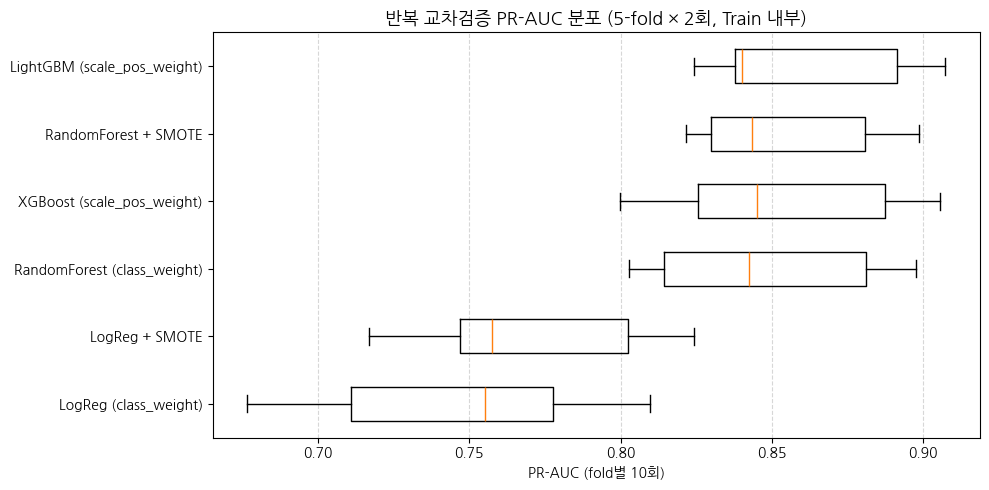

교차검증 CSV 2개 저장 완료!


,Model,PR_AUC_mean,PR_AUC_std,Flagged_mean,Flagged_std,Fit_Seconds_mean
0,LightGBM (scale_pos_weight),0.8602,0.0344,58.6,2.8752,4.0183
1,RandomForest + SMOTE,0.8548,0.0298,59.9,2.6854,28.8023
2,XGBoost (scale_pos_weight),0.8534,0.0378,60.9,2.2828,1.4633
3,RandomForest (class_weight),0.8470,0.0367,60.3,2.4060,16.6269
4,LogReg + SMOTE,0.7707,0.0366,74.0,6.8961,1.0024
5,LogReg (class_weight),0.7468,0.0447,79.7,22.1813,0.7895


In [14]:
# ============================================================
# 교차검증 결과 요약 · 그래프 · 저장
# 정렬: PR-AUC 평균이 높은 순
# 저장: reports/tables/supervised_cv_folds.csv (fold별), supervised_cv_summary.csv (모델별 요약)
# ============================================================
import matplotlib.pyplot as plt

cv_summary = (
    cv_folds.groupby("Model")
    .agg(
        PR_AUC_mean=("PR_AUC", "mean"),
        PR_AUC_std=("PR_AUC", "std"),
        Flagged_mean=("Flagged_at_Recall_0.8", "mean"),
        Flagged_std=("Flagged_at_Recall_0.8", "std"),
        Fit_Seconds_mean=("Fit_Seconds", "mean"),
    )
    .sort_values("PR_AUC_mean", ascending=False)
    .reset_index()
)

# 모델별 fold 10개의 PR-AUC 분포 (상자 = 중간 50%, 가운데 선 = 중앙값)
order = cv_summary["Model"].tolist()
fig, ax = plt.subplots(figsize=(10, 5))
ax.boxplot([cv_folds.loc[cv_folds["Model"] == m, "PR_AUC"] for m in order], vert=False)
ax.set_yticks(range(1, len(order) + 1), order)
ax.invert_yaxis()
ax.set_xlabel("PR-AUC (fold별 10회)")
ax.set_title("반복 교차검증 PR-AUC 분포 (5-fold × 2회, Train 내부)", fontsize=13)
ax.grid(True, axis="x", linestyle="--", alpha=0.5)
plt.tight_layout()
plt.savefig(PROJECT_ROOT / "reports" / "figures" / "supervised_cv_pr_auc.png", dpi=300)
plt.show()

cv_folds.to_csv(TABLE_DIR / "supervised_cv_folds.csv", index=False, encoding="utf-8-sig")
cv_summary.to_csv(TABLE_DIR / "supervised_cv_summary.csv", index=False, encoding="utf-8-sig")
print("교차검증 CSV 2개 저장 완료!")

display(cv_summary.round(4))

### 6.1 결과 해석

| 순위 | 모델 | PR-AUC (평균 ± 편차) | Recall 0.8 검토 건수 (평균) | 학습 시간 |
|---|---|---|---|---|
| 1 | LightGBM (scale_pos_weight) | **0.860 ± 0.034** | 58.6 | 4.0초 |
| 2 | RandomForest + SMOTE | 0.855 ± 0.030 | 59.9 | 28.8초 |
| 3 | XGBoost (scale_pos_weight) | 0.853 ± 0.038 | 60.9 | 1.5초 |
| 4 | RandomForest (class_weight) | 0.847 ± 0.037 | 60.3 | 16.6초 |
| 5 | LogReg + SMOTE | 0.771 ± 0.037 | 74.0 | 1.0초 |
| 6 | LogReg (class_weight) | 0.747 ± 0.045 | 79.7 | 0.8초 |

- **트리 모델 4개(0.847~0.860)는 로지스틱 회귀(0.747~0.771)보다 확실히 낫습니다.** 차이(약 0.08~0.11)가 표준편차(약 0.03~0.04)보다 훨씬 큽니다.
- **트리 모델끼리의 차이(최대 0.013)는 표준편차보다 작아서 "사실상 비슷하다"** 고 봐야 합니다. 같은 fold끼리 짝지어 비교하면 LightGBM이 RF(class_weight)를 10번 중 8번 이겨 약간의 우위는 있지만, 운영 모델로 RF를 고른 판단을 뒤집을 만큼은 아닙니다.
- **SMOTE vs class_weight**: 로지스틱 회귀에서는 SMOTE가 +0.024(10번 중 8번 승), RF에서는 +0.008(7번 승)입니다. 선형 모델에서 효과가 더 크고, 트리 모델에서는 작으면서 학습 시간은 약 1.7배 늘어납니다.
- **LightGBM**은 기본 설정으로는 무너졌고, `boost_from_average=False`와 `reg_lambda=1`을 넣은 뒤에야 가장 좋은 성능이 나왔습니다. 극불균형에서는 라이브러리 기본값을 꼭 점검해야 합니다.